In [ ]:
import pandas as pd
import numpy as np
from collections import Counter
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/kaggle/input/new-roles-datasets/Cleaned/general_test.csv").reset_index(drop=False).rename(columns={"index":"row_id"})

p0 = pd.read_parquet("/kaggle/input/qwen2-5-1-5b-classification-general-0/preds_shard0.parquet")
p1 = pd.read_parquet("/kaggle/input/qwen2-5-1-5b-classification-general-new-1/preds_shard1.parquet")
p2 = pd.read_parquet("/kaggle/input/qwen2-5-1-5b-classification-general-2/preds_shard2.parquet")

preds_all = pd.concat([p0, p1, p2], ignore_index=True)
assert preds_all["row_id"].is_unique, "Duplicate row_ids in merged preds!"

df = df.merge(preds_all, on="row_id", how="left")
missing = df["pred"].isna().sum()
if missing:
    print(f"WARNING: {missing} rows missing predictions")

df = df.drop(["row_id"], axis=1)

if "clean_data" in df.columns:
    df.rename(columns={"clean_data": "text"}, inplace=True)

print(f"Loaded {len(df)} rows.")
display(df.head(3))

Loaded 119426 rows.


,role,text,pred
0,Sheldon Cooper,"ah , it 's quite elementary . the word ' happy...",Gregory House
1,Sheldon Cooper,"certainly . given that "" happy "" , "" joyful "" ...",Gregory House
2,Sheldon Cooper,assuming that you 're requesting the antonym f...,Sheldon Cooper


In [3]:
def normalize_role(s):
    return str(s).strip().lower().replace(".", "")

df["role_norm"] = df["role"].apply(normalize_role)
df["pred_norm"] = df["pred"].apply(normalize_role)
df["correct"] = df["role_norm"] == df["pred_norm"]

OUTPUT_PATH = "/kaggle/working/general_test_results.csv"
df.to_csv(OUTPUT_PATH, index=False)

accuracy = df["correct"].mean()
print(f"\nOverall Accuracy: {accuracy:.2%} ({df['correct'].sum()} / {len(df)})")
print(f"Results saved to: {OUTPUT_PATH}")


Overall Accuracy: 15.46% (18464 / 119426)
Results saved to: /kaggle/working/general_test_results.csv


In [4]:
labels = sorted(df["role_norm"].unique())
support = df.groupby("role_norm").size().reindex(labels, fill_value=0)
tp = df[df["correct"]].groupby("role_norm").size().reindex(labels, fill_value=0)
pred_counts = df.groupby("pred_norm").size().reindex(labels, fill_value=0)
fp = (pred_counts - tp).clip(lower=0)
fn = (support - tp).clip(lower=0)

precision = (tp / (tp + fp).replace(0, np.nan)).fillna(0.0)
recall    = (tp / (tp + fn).replace(0, np.nan)).fillna(0.0)
f1        = (2 * precision * recall / (precision + recall).replace(0, np.nan)).fillna(0.0)

display_name = df.groupby("role_norm")["role"].agg(lambda s: Counter(s).most_common(1)[0][0]).reindex(labels)

per_label = pd.DataFrame({
    "label": display_name.values,
    "support": support.values,
    "tp": tp.values,
    "fp": fp.values,
    "fn": fn.values,
    "precision": precision.values,
    "recall": recall.values,
    "f1": f1.values,
}).sort_values(["recall","support"], ascending=[False, False]).reset_index(drop=True)

pd.set_option('display.max_rows', None)

print("\nPer-label metrics (sorted by recall desc):")
display(per_label)


Per-label metrics (sorted by recall desc):


,label,support,tp,fp,fn,precision,recall,f1
0,Fred Flintstone,1440,1343,12764,97,0.095201,0.932639,0.172766
1,Jeff Spicoli,1446,1216,1893,230,0.391123,0.840941,0.533919
2,Jack Sparrow,1405,1164,2729,241,0.298998,0.828470,0.439411
3,The Dude,1394,1062,6742,332,0.136084,0.761836,0.230920
4,Dr. Frank-N-Furter,1399,876,2418,523,0.265938,0.626162,0.373322
5,Karl Childers,1344,756,700,588,0.519231,0.562500,0.540000
6,Sheldon Cooper,1420,714,7768,706,0.084178,0.502817,0.144213
7,Gaston,1358,506,415,852,0.549403,0.372607,0.444054
8,Mater,1433,523,2488,910,0.173696,0.364969,0.235374
9,Jackie Moon,1380,458,367,922,0.555152,0.331884,0.415420


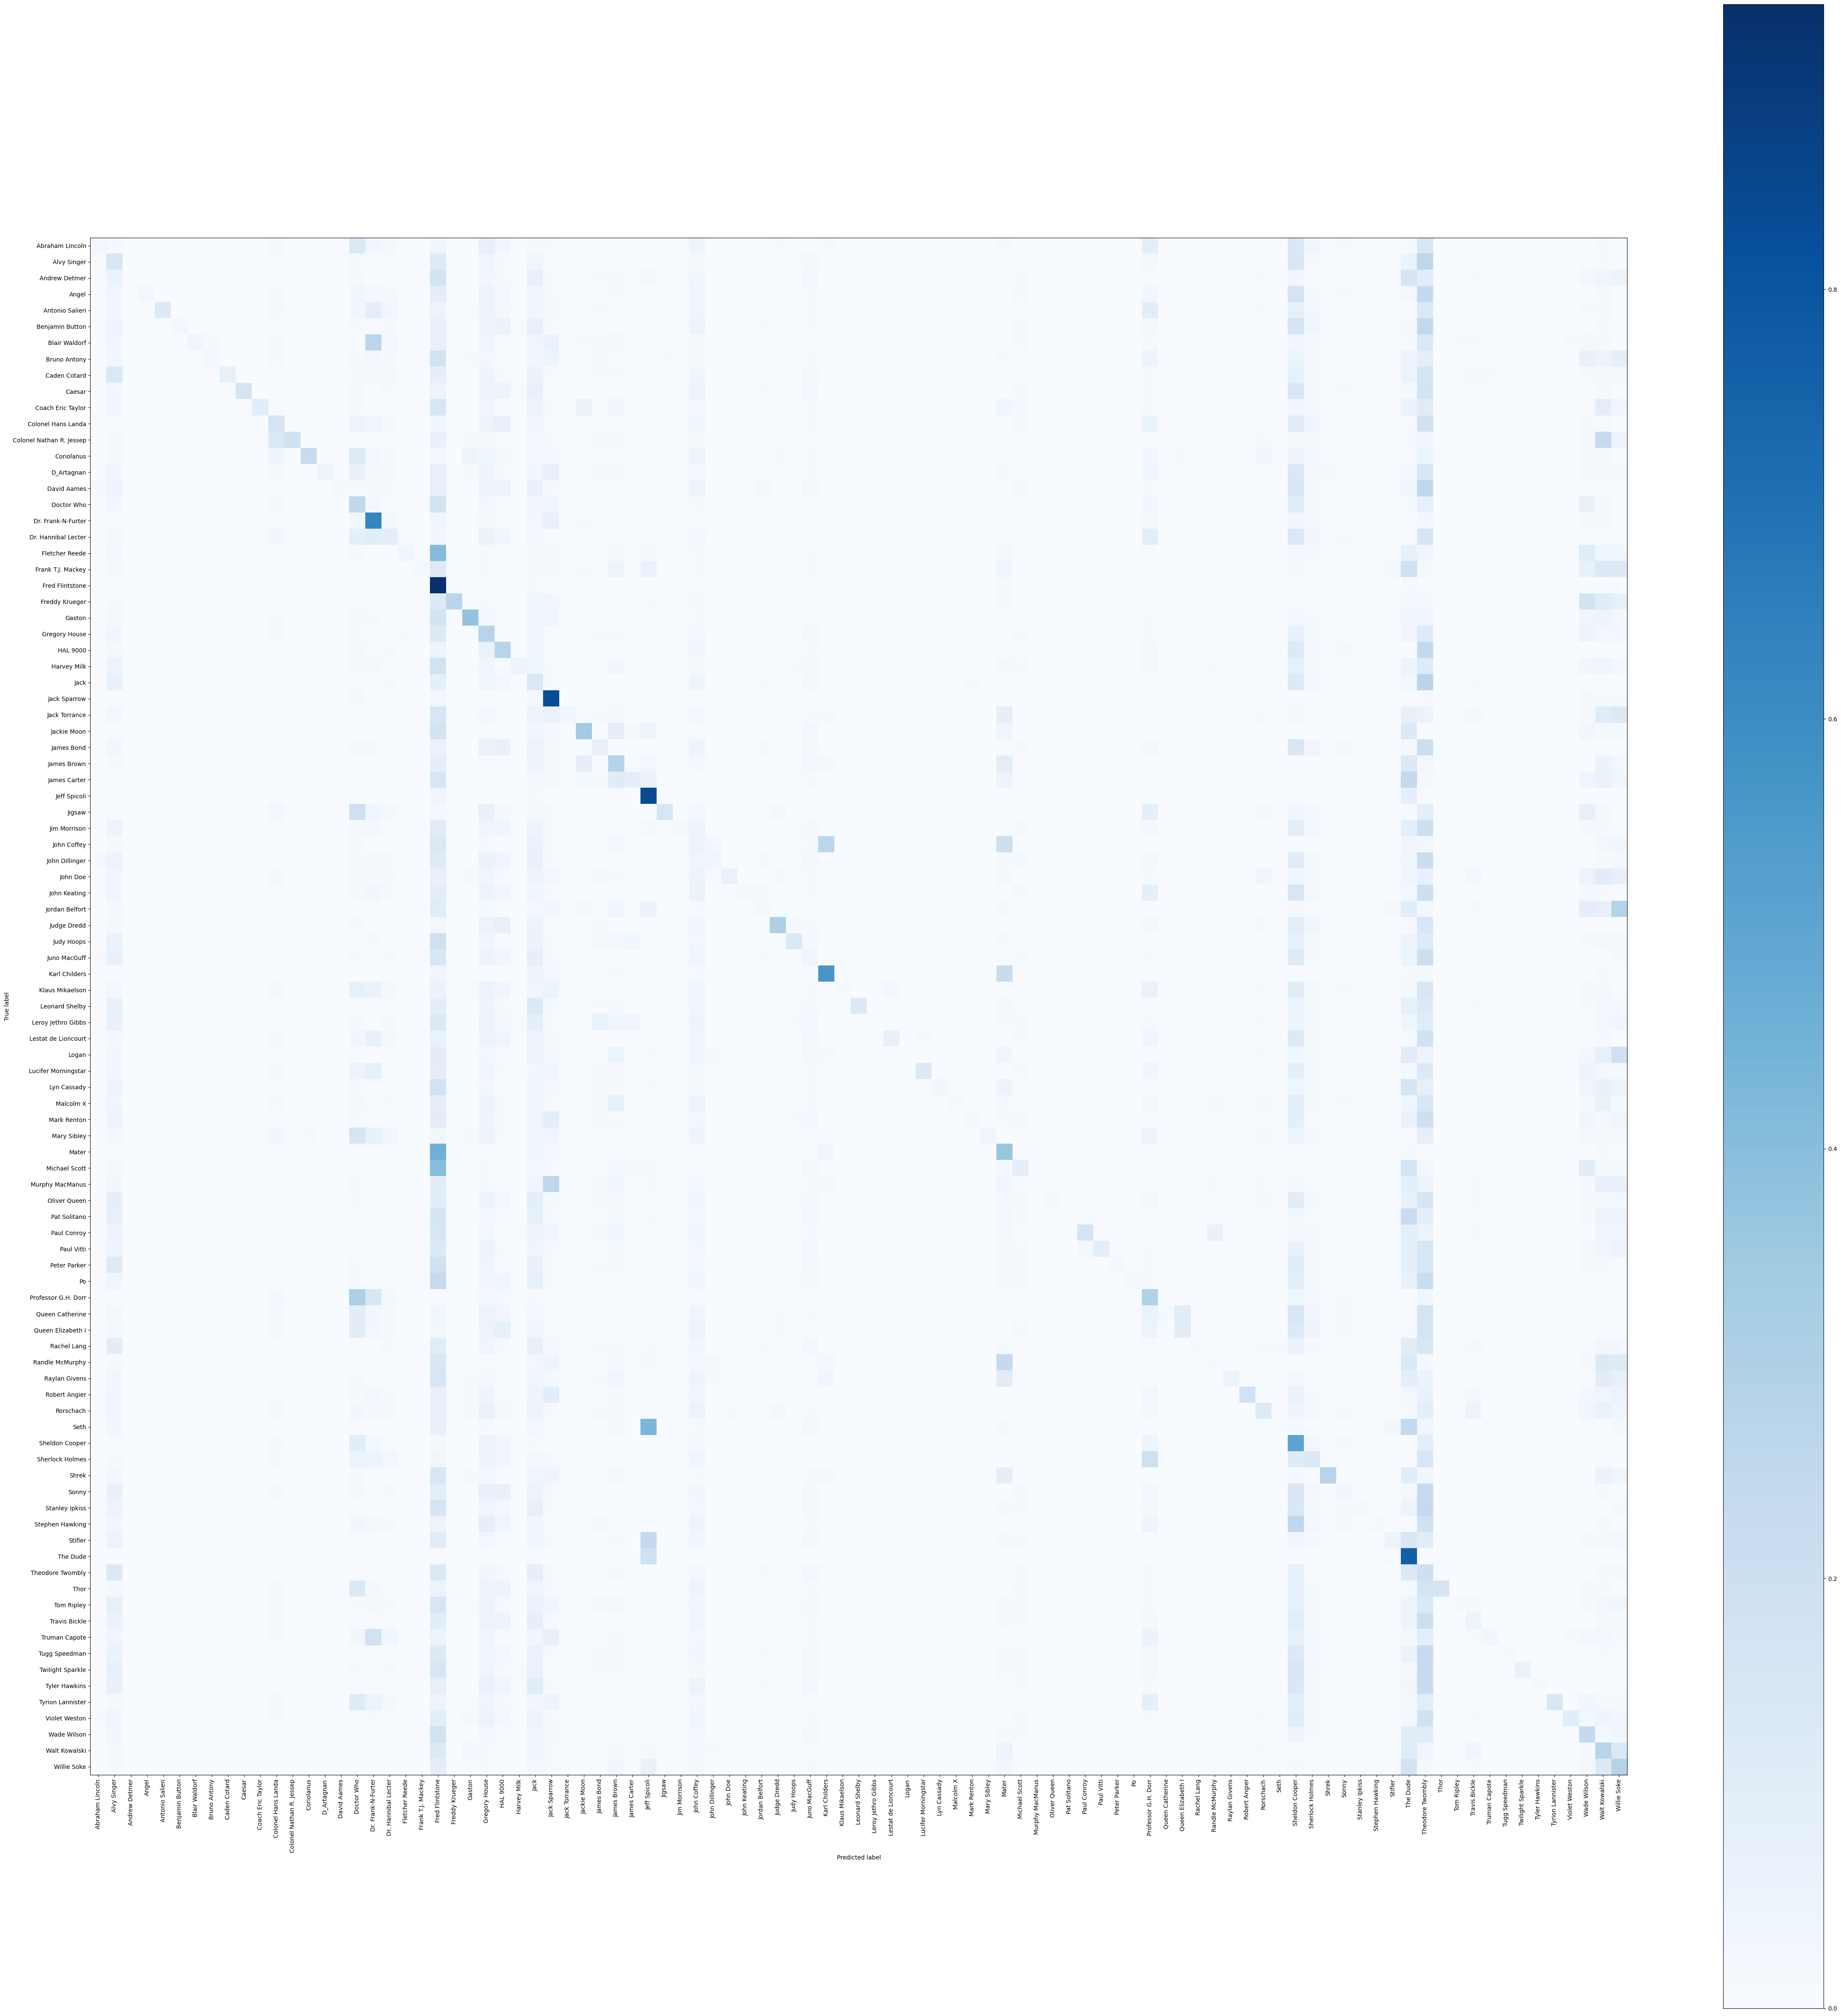

In [ ]:
fig_size_val = max(8, len(labels) * 0.5)
fig, ax = plt.subplots(figsize=(fig_size_val, fig_size_val))
labels = sorted(df["role_norm"].unique())
label_display_map = df.set_index("role_norm")["role"].to_dict()
display_labels = [label_display_map.get(l, l) for l in labels]

cmp = ConfusionMatrixDisplay.from_predictions(
    df["role_norm"], 
    df["pred_norm"], 
    labels=labels,
    display_labels=display_labels,
    normalize='true',
    include_values=False,
    cmap=plt.cm.Blues,
    xticks_rotation=90,
    ax=ax,
)

plt.tight_layout()
plt.show()